# 07 — Backtest 003: Bandas de Bollinger em mercado lateral (EURUSD H4 · H1 · M15)

**Hipótese:** quando o mercado está **lateral**, o preço tende a voltar para a média. Então dá para
**comprar no fundo da banda** e **vender no topo da banda**, sempre com alvo **no meio da banda**.

**Regras do setup (como você descreveu):**

| Item | Regra |
|---|---|
| Bandas | Bollinger de **21 períodos**, 2 desvios-padrão. O "meio da banda" é a média de 21 |
| Filtro de lateralidade | A **média longa de 200 está lateral**: andou menos que *k* × ATR nas últimas 20 barras |
| Compra | Fechamento **abaixo da banda inferior** → compra na abertura da barra seguinte |
| Venda | Fechamento **acima da banda superior** → venda na abertura da barra seguinte |
| Saída | Quando uma barra **fecha no meio da banda ou além** (média de 21) |
| Proteção | Stop de *N* × ATR (você não definiu stop; testamos um largo e outros mais curtos) |

**Regras de day trade (padrão do laboratório):** sinal só entre 9h e 21h (horário do servidor da XM),
zera tudo às 23h, spread alargado na virada do dia, custos completos (spread de cada barra + slippage;
comissão como sensibilidade).

**Como vamos validar:**
1. Rodar a **regra padrão** (exatamente como descrita) nos três tempos gráficos.
2. Testar uma **grade pequena** de variações **só no período de treino** (dentro da amostra).
3. Levar a melhor variação para o período **fora da amostra**, que ela nunca viu.
4. Comparar com **entradas aleatórias** que também apostam na volta à média.
5. Aplicar os **critérios de aprovação** do laboratório.

> Sem look-ahead: todo sinal usa só a barra **fechada**; a entrada é sempre na abertura da barra seguinte.

## 1. Configuração
Todos os parâmetros ficam aqui em cima, para você poder mudar e rodar de novo.

In [ ]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

# ---------------- setup ----------------
BACKTEST_ID = "003"
SIMBOLO = "EURUSD"
TFS = ["H4", "H1", "M15"]
DATA_INICIO = "2010-01-01"  # H4/H1 (o M15 só tem dados desde out/2022)

BB_PERIODO, BB_DESVIOS = 21, 2.0
MEDIA_LONGA = 200
LATERAL_BARRAS = 20  # inclinação da média de 200 medida em 20 barras
ATR_PERIODO = 14

# ---------------- regra padrão (como descrita) ----------------
PADRAO = {"gatilho": "fechou fora", "lateral_k": 0.5, "stop_atr": 3.0, "zerar": True}

# ---------------- grade de variações (testada só no treino) ----------------
GRADE_GATILHO = ["fechou fora", "voltou para dentro"]
GRADE_LATERAL = [None, 1.0, 0.5, 0.25]  # None = sem filtro
GRADE_STOP = [1.5, 2.0, 3.0]
GRADE_ZERAR = [True, False]

# ---------------- day trade ----------------
SESSAO = (9, 21)  # hora de FECHAMENTO da barra de sinal (servidor XM)
HORA_ZERAR = 23
MULT_SPREAD_VIRADA = 1.5

# ---------------- custos e risco ----------------
SLIPPAGE_PONTOS = 2  # por lado
COMISSAO_USD_LOTE = 0.0  # XM Standard = 0 (sensibilidade com 7)
RISCO_POR_TRADE = 0.01

# ---------------- validação ----------------
INICIO_OOS = {"H4": "2021-01-01", "H1": "2021-01-01", "M15": "2025-01-01"}
MIN_TRADES_TREINO = 60
N_SIM, SEED = 300, 42
MIN_TRADES_SEMANA, MAX_INTERVALO_P90 = 2.0, 5

RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dados" / "xm").is_dir()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError(f"Não encontrei a pasta dados/xm a partir de {Path.cwd()}")
PASTA_DADOS = RAIZ / "dados" / "xm"
sys.path.insert(0, str(RAIZ / "src"))
from lhsquant.estilo import aplicar_estilo, CORES

aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
info = pd.read_parquet(PASTA_DADOS / "info_simbolos.parquet")
info = info[info["simbolo"] == SIMBOLO].iloc[-1]
PONTO, CONTRATO = float(info["ponto"]), float(info["contrato"])
SLIP = SLIPPAGE_PONTOS * PONTO
print(
    f"{SIMBOLO}: ponto {PONTO} | slippage {SLIPPAGE_PONTOS} pontos por lado | OOS a partir de {INICIO_OOS}"
)

EURUSD: ponto 1e-05 | slippage 2 pontos por lado | OOS a partir de {'H4': '2021-01-01', 'H1': '2021-01-01', 'M15': '2025-01-01'}


## 2. Dados e indicadores (sem look-ahead)

- **Bandas de Bollinger:** média de 21 fechamentos ± 2 desvios-padrão desses mesmos 21 fechamentos.
- **Média longa lateral:** comparamos a média de 200 de agora com a de 20 barras atrás. Se a diferença
  for menor que *k* × ATR, consideramos o mercado **lateral**. Dividir pelo ATR deixa a régua igual
  em qualquer tempo gráfico e em qualquer época (volatilidade alta ou baixa).
- Tudo é calculado no **fechamento** de cada barra, e o motor só usa o valor da barra já fechada.

In [ ]:
DUR_H = {"H4": 4, "H1": 1, "M15": 0.25}
HORAS_VIRADA = {
    "H4": (20, 0),
    "H1": (22, 23, 0),
    "M15": (22, 23, 0),
}  # hora de ABERTURA da barra


def carregar(tf):
    df = pd.read_parquet(PASTA_DADOS / SIMBOLO / f"{tf}.parquet").sort_index()
    return df.loc[DATA_INICIO:]


def calc_atr(df, n=ATR_PERIODO):
    h, l, c = df["maxima"], df["minima"], df["fechamento"]
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(
        axis=1
    )
    return tr.ewm(alpha=1 / n, adjust=False).mean()


def preparar(tf):
    df = carregar(tf)
    c = df["fechamento"]
    meio = c.rolling(BB_PERIODO).mean()
    dp = c.rolling(BB_PERIODO).std(ddof=0)
    longa = c.rolling(MEDIA_LONGA).mean()
    atr = calc_atr(df)
    idx = df.index
    fecha = idx + pd.Timedelta(hours=DUR_H[tf])
    dia = idx.normalize()
    ultimo_do_dia = np.append(dia[1:] != dia[:-1], True)
    mult = np.where(np.isin(idx.hour, HORAS_VIRADA[tf]), MULT_SPREAD_VIRADA, 1.0)
    return {
        "idx": idx,
        "o": df["abertura"].to_numpy(float),
        "h": df["maxima"].to_numpy(float),
        "l": df["minima"].to_numpy(float),
        "c": c.to_numpy(float),
        "spr": df["spread"].to_numpy(float) * PONTO * mult,
        "atr": atr.to_numpy(float),
        "meio": meio.to_numpy(float),
        "inf": (meio - BB_DESVIOS * dp).to_numpy(float),
        "sup": (meio + BB_DESVIOS * dp).to_numpy(float),
        # inclinação da média de 200 em unidades de ATR
        "incl": ((longa - longa.shift(LATERAL_BARRAS)).abs() / atr).to_numpy(float),
        "pode": np.asarray((fecha.hour >= SESSAO[0]) & (fecha.hour < SESSAO[1])),
        "zerar_dia": np.asarray((fecha.hour >= HORA_ZERAR) | ultimo_do_dia),
        "fim_dados": np.append(np.zeros(len(idx) - 1, bool), True),
    }


D = {tf: preparar(tf) for tf in TFS}
for tf, a in D.items():
    lat = a["incl"][~np.isnan(a["incl"])]
    print(
        f"{tf:>3}: {len(a['idx']):>7,} barras | {a['idx'][0]:%Y-%m-%d} → {a['idx'][-1]:%Y-%m-%d} | "
        f"tempo lateral: k=1,0 {np.mean(lat < 1.0):.0%} · k=0,5 {np.mean(lat < 0.5):.0%} · k=0,25 {np.mean(lat < 0.25):.0%} | "
        f"spread mediano {np.median(a['spr']) / 0.0001:.1f} pip"
    )

 H4:  26,132 barras | 2010-01-04 → 2026-10-20 | tempo lateral: k=1,0 70% · k=0,5 39% · k=0,25 20% | spread mediano 1.6 pip
 H1: 100,066 barras | 2010-09-02 → 2026-10-21 | tempo lateral: k=1,0 68% · k=0,5 38% · k=0,25 20% | spread mediano 1.6 pip
M15: 100,269 barras | 2022-10-06 → 2026-10-21 | tempo lateral: k=1,0 67% · k=0,5 39% · k=0,25 19% | spread mediano 1.7 pip


## 3. Os sinais

Testamos duas formas de "chegar no fundo/topo da banda":

- **fechou fora** (a regra como você descreveu): a barra fechou **abaixo** da banda inferior → compra;
  fechou **acima** da superior → venda.
- **voltou para dentro** (variação comum): a barra anterior fechou fora e a atual fechou **de volta dentro**
  da banda. Espera o preço "mostrar" que parou de cair (ou de subir) antes de entrar.

Os dois só valem se o filtro de lateralidade estiver ligado naquela barra.

In [ ]:
def sinais(a, gatilho, lateral_k):
    c, inf, sup = a["c"], a["inf"], a["sup"]
    if gatilho == "fechou fora":
        compra, venda = c < inf, c > sup
    else:
        c1, inf1, sup1 = np.roll(c, 1), np.roll(inf, 1), np.roll(sup, 1)
        compra = (c1 < inf1) & (c >= inf) & (c < a["meio"])
        venda = (c1 > sup1) & (c <= sup) & (c > a["meio"])
        compra[0] = venda[0] = False
    ok = ~np.isnan(a["incl"]) & ~np.isnan(inf)
    if lateral_k is not None:
        ok &= a["incl"] < lateral_k
    return np.where(ok & compra, 1, np.where(ok & venda, -1, 0)).astype(np.int64)


for tf, a in D.items():
    s = sinais(a, **{k: PADRAO[k] for k in ("gatilho", "lateral_k")})
    print(
        f"{tf:>3}: {np.sum(s == 1):>5} sinais de compra | {np.sum(s == -1):>5} de venda (regra padrão, antes da sessão)"
    )

 H4:   658 sinais de compra |   635 de venda (regra padrão, antes da sessão)
 H1:  2852 sinais de compra |  2722 de venda (regra padrão, antes da sessão)
M15:  2438 sinais de compra |  2701 de venda (regra padrão, antes da sessão)


## 4. O motor (barra a barra, com numba)

Para cada barra:
1. **Com posição:** primeiro o **stop** dentro da barra (de forma conservadora: se o stop foi tocado,
   assumimos que saiu nele). Depois, no **fechamento**: saída no **meio da banda**, ou zerar no fim do dia.
2. **Sem posição:** se há sinal, dentro da sessão, entra na **abertura da próxima barra**.

Custos: os preços do MT5 são de *bid*. A compra entra no *ask* (bid + spread) e a venda sai no *ask*.
Slippage de 2 pontos em cada lado. O resultado é medido em **R** (1 R = distância até o stop).

In [ ]:
@njit(cache=True)
def motor(o, h, l, c, spr, atr, meio, sinal, pode, zerar, stop_atr, slip, comis):
    n = len(c)
    cap = n // 2 + 10
    ent = np.empty(cap, np.int64)
    sai = np.empty(cap, np.int64)
    dire = np.empty(cap, np.int64)
    mot = np.empty(cap, np.int64)
    rl = np.empty(cap)
    rb = np.empty(cap)
    nt, pos = 0, 0
    stop, e_l, e_b, risco = 0.0, 0.0, 0.0, 1.0
    for t in range(1, n):
        if pos != 0:
            px, m = 0.0, 0
            if pos == 1 and l[t] <= stop:
                px, m = min(o[t], stop), 1
            elif pos == -1 and h[t] + spr[t] >= stop:
                px, m = max(o[t] + spr[t], stop), 1
            if m == 0:
                if (pos == 1 and c[t] >= meio[t]) or (pos == -1 and c[t] <= meio[t]):
                    m = 2
                elif zerar[t]:
                    m = 3
                elif t == n - 1:
                    m = 4
                if m != 0:
                    px = c[t] if pos == 1 else c[t] + spr[t]
            if m != 0:
                if pos == 1:
                    x_b, x_l = px, px - slip
                else:
                    x_b, x_l = px - spr[t], px + slip
                rb[nt] = pos * (x_b - e_b) / risco
                rl[nt] = (pos * (x_l - e_l) - comis) / risco
                sai[nt], mot[nt] = t, m
                nt += 1
                pos = 0
            continue
        if sinal[t] == 0 or not pode[t] or zerar[t] or t + 1 >= n:
            continue
        d, j = sinal[t], t + 1
        if (d == 1 and o[j] >= meio[t]) or (d == -1 and o[j] <= meio[t]):
            continue  # abriu já no alvo: não há o que buscar
        e_b = o[j]
        if d == 1:
            e_l = o[j] + spr[j] + slip
            stop = e_l - stop_atr * atr[t]
        else:
            e_l = o[j] - slip
            stop = e_l + stop_atr * atr[t]
        risco = abs(e_l - stop)
        pos = d
        ent[nt], dire[nt] = j, d
    return ent[:nt], sai[:nt], dire[:nt], mot[:nt], rl[:nt], rb[:nt]


MOTIVOS = np.array(["", "stop", "meio da banda", "fim do dia", "fim dos dados"])


def rodar(
    tf, gatilho, lateral_k, stop_atr, zerar, comissao=COMISSAO_USD_LOTE, sinal=None
):
    a = D[tf]
    s = sinais(a, gatilho, lateral_k) if sinal is None else sinal
    z = a["zerar_dia"] if zerar else a["fim_dados"]
    ent, sai, d, m, rl, rb = motor(
        a["o"],
        a["h"],
        a["l"],
        a["c"],
        a["spr"],
        a["atr"],
        a["meio"],
        s,
        a["pode"],
        z,
        float(stop_atr),
        SLIP,
        comissao / CONTRATO,
    )
    return pd.DataFrame(
        {
            "entrada": a["idx"][ent],
            "saida": a["idx"][sai],
            "direcao": d,
            "motivo": MOTIVOS[m],
            "R": rl,
            "R_bruto": rb,
            "barras": sai - ent + 1,
        }
    )

### Métricas
As mesmas dos backtests anteriores: nº de operações, taxa de acerto, payoff, expectativa (com e sem custos),
fator de lucro, retorno com 1% de risco por operação, drawdown máximo, Sharpe, Sortino e frequência de day trade.

In [ ]:
def frequencia(tr, ini, fim):
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    d_ent = np.sort(
        tr["entrada"].dt.normalize().unique().to_numpy().astype("datetime64[D]")
    )
    pontos = np.concatenate(
        [
            [np.datetime64(ini.normalize(), "D")],
            d_ent,
            [np.datetime64(fim.normalize(), "D")],
        ]
    )
    gaps = np.busday_count(pontos[:-1], pontos[1:])
    gaps = gaps[gaps > 0] if (gaps > 0).any() else np.array([len(dias)])
    return {
        "Trades/semana": len(tr) / (len(dias) / 5),
        "Intervalo p90 (dias úteis)": float(np.percentile(gaps, 90)),
    }


def metricas(tr, ini, fim):
    tr = tr[(tr["entrada"] >= ini) & (tr["entrada"] <= fim)]
    if len(tr) == 0:
        return pd.Series({"Nº trades": 0})
    r = tr["R"]
    g, p = r[r > 0], r[r <= 0]
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    ret_d = (
        tr.groupby(tr["saida"].dt.normalize())["R"].sum() * RISCO_POR_TRADE
    ).reindex(dias, fill_value=0.0)
    neg = np.minimum(ret_d, 0)
    return pd.Series(
        {
            "Nº trades": len(tr),
            "Win rate %": len(g) / len(tr) * 100,
            "Payoff": g.mean() / abs(p.mean()) if len(p) and len(g) else np.nan,
            "Expectativa R": r.mean(),
            "Expectativa R sem custos": tr["R_bruto"].mean(),
            "Fator de lucro": g.sum() / abs(p.sum()) if len(p) else np.nan,
            "Retorno % (1% risco)": (cap.iloc[-1] - 1) * 100,
            "Máx. drawdown %": (cap / cap.cummax() - 1).min() * 100,
            "Sharpe": ret_d.mean() / ret_d.std() * np.sqrt(252)
            if ret_d.std() > 0
            else np.nan,
            "Sortino": ret_d.mean() / np.sqrt((neg**2).mean()) * np.sqrt(252)
            if (neg < 0).any()
            else np.nan,
            **frequencia(tr, ini, fim),
        }
    )


def dd_ano(r):
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    return (cap / cap.cummax() - 1).min() * 100


def periodos(tf):
    a = D[tf]
    oos = pd.Timestamp(INICIO_OOS[tf])
    return {
        "treino": (a["idx"][0], oos - pd.Timedelta(seconds=1)),
        "fora": (oos, a["idx"][-1]),
    }

## 5. A regra padrão, exatamente como descrita

Bollinger 21, filtro lateral com *k* = 0,5, entrada quando **fecha fora** da banda, saída no meio,
stop largo de 3 ATR (só para não deixar a operação sem proteção) e zerando no fim do dia.
Nada foi otimizado aqui.

In [ ]:
linhas = {}
for tf in TFS:
    tr = rodar(tf, **PADRAO)
    for nome, (ini, fim) in periodos(tf).items():
        linhas[(tf, nome)] = metricas(tr, ini, fim)
RES_PADRAO = pd.DataFrame(linhas)
display(
    RES_PADRAO.loc[
        [
            "Nº trades",
            "Win rate %",
            "Payoff",
            "Expectativa R sem custos",
            "Expectativa R",
            "Fator de lucro",
            "Máx. drawdown %",
            "Sharpe",
            "Trades/semana",
        ]
    ].round(2)
)

H4                H1             M15        
                          treino    fora    treino    fora  treino    fora
Nº trades                326.000 156.000 1,163.000 653.000 821.000 630.000
Win rate %                44.480  46.150    49.010  49.160  57.000  57.780
Payoff                     0.830   0.930     0.910   0.920   0.690   0.590
Expectativa R sem custos  -0.030  -0.000     0.000   0.030   0.080   0.050
Expectativa R             -0.050  -0.030    -0.030  -0.030  -0.030  -0.070
Fator de lucro             0.660   0.790     0.880   0.890   0.910   0.800
Máx. drawdown %          -16.540  -7.400   -42.330 -25.210 -41.100 -39.310
Sharpe                    -0.770  -0.420    -0.540  -0.500  -0.750  -1.700
Trades/semana              0.570   0.520     2.160   2.160   7.030   6.690

**Como ler:** compare a linha **"Expectativa R sem custos"** com **"Expectativa R"** (líquida). A diferença é
o quanto spread e slippage comem de cada operação. Se nem sem custos a expectativa é positiva, o setup não
tem vantagem bruta.

## 6. Grade de variações (só no período de treino)

São 48 combinações por tempo gráfico: 2 gatilhos × 4 filtros (incluindo **sem filtro**) × 3 stops × zerar ou não.
Escolhemos a melhor **só pelo treino** (maior expectativa líquida, com pelo menos 60 operações). O período fora
da amostra fica guardado para o teste final.

In [7]:
grade = []
for tf in TFS:
    (ti, tfim), (oi, ofim) = periodos(tf).values()
    for g in GRADE_GATILHO:
        for k in GRADE_LATERAL:
            for st in GRADE_STOP:
                for z in GRADE_ZERAR:
                    tr = rodar(tf, g, k, st, z)
                    mt, mo = metricas(tr, ti, tfim), metricas(tr, oi, ofim)
                    grade.append(
                        {
                            "tf": tf,
                            "gatilho": g,
                            "lateral_k": k,
                            "stop_atr": st,
                            "zerar": z,
                            "trades_treino": mt.get("Nº trades", 0),
                            "exp_treino": mt.get("Expectativa R", np.nan),
                            "exp_bruta_treino": mt.get(
                                "Expectativa R sem custos", np.nan
                            ),
                            "trades_fora": mo.get("Nº trades", 0),
                            "exp_fora": mo.get("Expectativa R", np.nan),
                        }
                    )
GRADE = pd.DataFrame(grade)
GRADE["lateral_k"] = (
    GRADE["lateral_k"].astype(object).where(GRADE["lateral_k"].notna(), "sem filtro")
)

ESCOLHA = {}
for tf in TFS:
    g = GRADE[(GRADE["tf"] == tf) & (GRADE["trades_treino"] >= MIN_TRADES_TREINO)]
    melhor = g.sort_values("exp_treino", ascending=False).iloc[0]
    ESCOLHA[tf] = {
        "gatilho": melhor["gatilho"],
        "lateral_k": None
        if melhor["lateral_k"] == "sem filtro"
        else float(melhor["lateral_k"]),
        "stop_atr": float(melhor["stop_atr"]),
        "zerar": bool(melhor["zerar"]),
    }
    print(
        f"\n{tf}: {len(g)} combinações com ≥ {MIN_TRADES_TREINO} trades no treino | "
        f"positivas no treino (líquido): {(g['exp_treino'] > 0).sum()} | positivas sem custos: {(g['exp_bruta_treino'] > 0).sum()}"
    )
    display(
        g.sort_values("exp_treino", ascending=False)
        .head(5)
        .drop(columns="tf")
        .round(3)
        .reset_index(drop=True)
    )


H4: 48 combinações com ≥ 60 trades no treino | positivas no treino (líquido): 20 | positivas sem custos: 25


,gatilho,lateral_k,stop_atr,zerar,trades_treino,exp_treino,exp_bruta_treino,trades_fora,exp_fora
0,voltou para dentro,0.250,1.500,False,83.000,0.061,0.097,36.000,0.105
1,voltou para dentro,0.500,1.500,False,147.000,0.043,0.079,75.000,0.208
2,voltou para dentro,1.000,3.000,False,237.000,0.032,0.051,143.000,0.047
3,voltou para dentro,0.500,2.000,True,144.000,0.032,0.062,78.000,0.057
4,voltou para dentro,0.250,3.000,False,81.000,0.030,0.049,34.000,0.089



H1: 48 combinações com ≥ 60 trades no treino | positivas no treino (líquido): 0 | positivas sem custos: 30


,gatilho,lateral_k,stop_atr,zerar,trades_treino,exp_treino,exp_bruta_treino,trades_fora,exp_fora
0,voltou para dentro,0.500,3.000,True,968.000,-0.013,0.024,517.000,-0.019
1,voltou para dentro,1.000,3.000,False,"1,576.000",-0.014,0.020,891.000,-0.023
2,voltou para dentro,1.000,3.000,True,"1,628.000",-0.014,0.024,901.000,-0.044
3,voltou para dentro,sem filtro,3.000,False,"2,256.000",-0.016,0.019,"1,246.000",-0.042
4,voltou para dentro,sem filtro,3.000,True,"2,330.000",-0.020,0.017,"1,266.000",-0.065



M15: 48 combinações com ≥ 60 trades no treino | positivas no treino (líquido): 0 | positivas sem custos: 48


,gatilho,lateral_k,stop_atr,zerar,trades_treino,exp_treino,exp_bruta_treino,trades_fora,exp_fora
0,fechou fora,0.500,3.000,False,821.000,-0.029,0.082,630.000,-0.063
1,fechou fora,0.500,3.000,True,821.000,-0.032,0.078,630.000,-0.069
2,voltou para dentro,0.250,3.000,False,387.000,-0.037,0.066,322.000,-0.124
3,voltou para dentro,0.250,3.000,True,387.000,-0.037,0.065,322.000,-0.126
4,voltou para dentro,0.500,3.000,False,763.000,-0.051,0.056,608.000,-0.090


**Atenção:** a melhor combinação do treino quase sempre parece boa, porque foi escolhida entre 48.
O que vale é como ela se sai **fora da amostra**, na próxima seção.

## 7. Fora da amostra e comparação com o acaso

Para cada tempo gráfico, a combinação escolhida no treino roda no período que ela nunca viu.

**Teste do acaso:** sorteamos entradas aleatórias **no mesmo regime** (mesmo filtro lateral e mesma sessão),
sempre apostando na volta à média (compra se o preço está abaixo do meio, venda se está acima), com as **mesmas
saídas e stop**. Se o setup não for melhor que isso, o "fundo da banda" não acrescenta nada.

H4: escolhida no treino → {'gatilho': 'voltou para dentro', 'lateral_k': 0.25, 'stop_atr': 1.5, 'zerar': False}
H1: escolhida no treino → {'gatilho': 'voltou para dentro', 'lateral_k': 0.5, 'stop_atr': 3.0, 'zerar': True}
M15: escolhida no treino → {'gatilho': 'fechou fora', 'lateral_k': 0.5, 'stop_atr': 3.0, 'zerar': False}


,H4,H1,M15
Nº trades,36.000,517.000,630.000
Win rate %,55.556,52.611,58.571
Payoff,0.988,0.829,0.579
Expectativa R,0.105,-0.019,-0.063
Expectativa R sem custos,0.165,0.036,0.059
Fator de lucro,1.235,0.920,0.819
Retorno % (1% risco),3.612,-10.350,-33.948
Máx. drawdown %,-4.675,-20.497,-37.041
Sharpe,0.228,-0.315,-1.578
Sortino,0.383,-0.433,-1.941


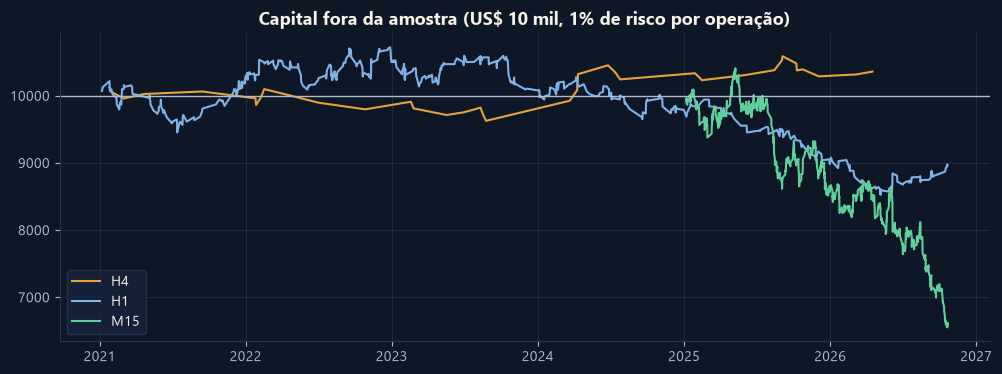

In [8]:
def aleatorio(tf, cfg, n_alvo, ini, fim, rng):
    a = D[tf]
    ok = (
        a["pode"]
        & ~np.isnan(a["incl"])
        & ~np.isnan(a["meio"])
        & (a["idx"] >= ini)
        & (a["idx"] <= fim)
    )
    if cfg["lateral_k"] is not None:
        ok &= a["incl"] < cfg["lateral_k"]
    elegiveis = np.flatnonzero(ok)
    s = np.zeros(len(a["c"]), np.int64)
    escolhidas = rng.choice(
        elegiveis, size=min(len(elegiveis), n_alvo * 3), replace=False
    )
    s[escolhidas] = np.where(a["c"][escolhidas] < a["meio"][escolhidas], 1, -1)
    return rodar(tf, sinal=s, **cfg)


rng = np.random.default_rng(SEED)
OOS, TR_OOS, P_VALOR = {}, {}, {}
for tf in TFS:
    oi, ofim = periodos(tf)["fora"]
    cfg = ESCOLHA[tf]
    tr = rodar(tf, **cfg)
    TR_OOS[tf] = tr[(tr["entrada"] >= oi)]
    m = metricas(tr, oi, ofim)
    sims = []
    for _ in range(N_SIM):
        ts = aleatorio(tf, cfg, int(m["Nº trades"]), oi, ofim, rng)
        sims.append(ts["R"].mean() if len(ts) else np.nan)
    sims = np.array(sims)
    P_VALOR[tf] = float(np.nanmean(sims >= m["Expectativa R"]))
    m["Aleatório: expectativa R"] = np.nanmean(sims)
    m["p-valor vs aleatório"] = P_VALOR[tf]
    m["Com comissão US$7: expectativa R"] = metricas(
        rodar(tf, comissao=7.0, **cfg), oi, ofim
    )["Expectativa R"]
    OOS[tf] = m
    print(f"{tf}: escolhida no treino → {cfg}")
RES_OOS = pd.DataFrame(OOS)
display(RES_OOS.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
for tf, cor in zip(TFS, [CORES["primaria"], CORES["secundaria"], CORES["positivo"]]):
    t_ = TR_OOS[tf].sort_values("saida")
    ax.plot(
        t_["saida"],
        10_000 * (1 + RISCO_POR_TRADE * t_["R"]).cumprod(),
        color=cor,
        label=tf,
    )
ax.axhline(10_000, color=CORES["texto_suave"], lw=1)
ax.set_title("Capital fora da amostra (US$ 10 mil, 1% de risco por operação)")
ax.legend()
plt.show()

## 8. O filtro de lateralidade faz diferença?

Mesma configuração escolhida, fora da amostra, **com** e **sem** o filtro da média de 200 lateral.
Se o resultado for parecido, o filtro não está ajudando.

In [9]:
comp = {}
for tf in TFS:
    oi, ofim = periodos(tf)["fora"]
    cfg = dict(ESCOLHA[tf])
    k = cfg["lateral_k"] if cfg["lateral_k"] is not None else PADRAO["lateral_k"]
    for nome, kk in [(f"com filtro (k={k})", k), ("sem filtro", None)]:
        cfg["lateral_k"] = kk
        m = metricas(rodar(tf, **cfg), oi, ofim)
        comp[(tf, nome)] = m[
            ["Nº trades", "Expectativa R sem custos", "Expectativa R", "Fator de lucro"]
        ]
display(pd.DataFrame(comp).round(3))

for tf in TFS:
    t_ = TR_OOS[tf]
    mot = (
        t_.groupby("motivo")["R"]
        .agg(["count", "mean"])
        .rename(columns={"count": "trades", "mean": "R médio"})
    )
    print(f"\n{tf} — como as operações terminaram (fora da amostra):")
    display(mot.round(3))

H4                            H1  \
                         com filtro (k=0.25) sem filtro com filtro (k=0.5)   
Nº trades                             36.000    200.000            517.000   
Expectativa R sem custos               0.165      0.150              0.036   
Expectativa R                          0.105      0.090             -0.019   
Fator de lucro                         1.235      1.209              0.920   

                                                   M15             
                         sem filtro com filtro (k=0.5) sem filtro  
Nº trades                 1,266.000            630.000  1,337.000  
Expectativa R sem custos     -0.006              0.059      0.034  
Expectativa R                -0.065             -0.063     -0.088  
Fator de lucro                0.760              0.819      0.765


H4 — como as operações terminaram (fora da amostra):


,trades,R médio
motivo,,
meio da banda,20,0.993
stop,16,-1.005



H1 — como as operações terminaram (fora da amostra):


,trades,R médio
motivo,,
fim do dia,269,-0.125
meio da banda,176,0.546
stop,72,-1.006



M15 — como as operações terminaram (fora da amostra):


,trades,R médio
motivo,,
meio da banda,425,0.394
stop,205,-1.011


## 9. Veredito

Os mesmos critérios dos backtests anteriores, aplicados ao **melhor tempo gráfico fora da amostra**
(maior expectativa líquida). O PBO não é calculado neste teste simples; no lugar dele, a escolha foi feita
só no treino e avaliada fora.

In [10]:
MELHOR_TF = max(TFS, key=lambda tf: OOS[tf]["Expectativa R"])
m = OOS[MELHOR_TF]
dd_anos = (
    TR_OOS[MELHOR_TF].groupby(TR_OOS[MELHOR_TF]["entrada"].dt.year)["R"].apply(dd_ano)
)
criterios = pd.DataFrame(
    [
        (
            "≥ 100 operações fora da amostra",
            f"{m['Nº trades']:.0f}",
            m["Nº trades"] >= 100,
        ),
        (
            "Expectativa > 0 R (líquida)",
            f"{m['Expectativa R']:+.3f}",
            m["Expectativa R"] > 0,
        ),
        (
            "Fator de lucro > 1,2",
            f"{m['Fator de lucro']:.2f}",
            m["Fator de lucro"] > 1.2,
        ),
        (
            "Melhor que aleatório (p < 0,05)",
            f"p = {P_VALOR[MELHOR_TF]:.3f}",
            P_VALOR[MELHOR_TF] < 0.05,
        ),
        ("Nenhum ano com DD > 20%", f"pior {dd_anos.min():.1f}%", dd_anos.min() > -20),
        (
            f"≥ {MIN_TRADES_SEMANA:g} trades/semana e p90 ≤ {MAX_INTERVALO_P90} dias úteis",
            f"{m['Trades/semana']:.1f}/sem · p90 {m['Intervalo p90 (dias úteis)']:.0f}",
            (m["Trades/semana"] >= MIN_TRADES_SEMANA)
            & (m["Intervalo p90 (dias úteis)"] <= MAX_INTERVALO_P90),
        ),
    ],
    columns=["Critério", "Valor", "Passou"],
)
criterios["Passou"] = criterios["Passou"].map({True: "✅", False: "❌"})
print(
    f"Melhor tempo gráfico fora da amostra: {MELHOR_TF} | configuração: {ESCOLHA[MELHOR_TF]}"
)
display(criterios)
APROVADO = (criterios["Passou"] == "✅").all()
print(
    "VEREDITO:",
    "✅ APROVADO"
    if APROVADO
    else f"❌ REPROVADO ({(criterios['Passou'] == '❌').sum()} de {len(criterios)} critérios falharam)",
)

Melhor tempo gráfico fora da amostra: H4 | configuração: {'gatilho': 'voltou para dentro', 'lateral_k': 0.25, 'stop_atr': 1.5, 'zerar': False}


,Critério,Valor,Passou
0,≥ 100 operações fora da amostra,36,❌
1,Expectativa > 0 R (líquida),+0.105,✅
2,"Fator de lucro > 1,2",1.23,✅
3,"Melhor que aleatório (p < 0,05)",p = 0.223,❌
4,Nenhum ano com DD > 20%,pior -3.0%,✅
5,≥ 2 trades/semana e p90 ≤ 5 dias úteis,0.1/sem · p90 99,❌


VEREDITO: ❌ REPROVADO (3 de 6 critérios falharam)


## 10. Salvar os resultados
Tudo vai para `backtests/003_bollinger_lateral_EURUSD_H4-H1-M15/`.

In [11]:
PASTA_BT = RAIZ / "backtests" / "003_bollinger_lateral_EURUSD_H4-H1-M15"
PASTA_BT.mkdir(parents=True, exist_ok=True)
params = {
    k: v
    for k, v in globals().items()
    if k.isupper()
    and isinstance(v, (int, float, str, list, dict, tuple, type(None)))
    and k not in ("D", "OOS", "TR_OOS", "ESCOLHA", "P_VALOR")
}
params["ESCOLHA"] = ESCOLHA
(PASTA_BT / "parametros.json").write_text(
    json.dumps(params, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)
RES_PADRAO.to_csv(PASTA_BT / "metricas_padrao.csv")
RES_OOS.to_csv(PASTA_BT / "metricas_oos.csv")
GRADE.to_csv(PASTA_BT / "grade_otimizacao.csv", index=False)
criterios.to_csv(PASTA_BT / "criterios.csv", index=False)
pd.concat([t.assign(tf=tf) for tf, t in TR_OOS.items()]).to_csv(
    PASTA_BT / "operacoes_oos.csv", index=False
)
print(f"Salvo em {PASTA_BT}")

Salvo em c:\Dev\GitHub\LHS Capital\lhs-quant-lab\backtests\003_bollinger_lateral_EURUSD_H4-H1-M15


## 11. Conclusões

**Veredito: ❌ reprovado (3 de 6 critérios).** O que os números mostraram:

1. **A regra padrão perde nos três tempos gráficos** depois dos custos (−0,03 a −0,07 R por operação fora da amostra).
   Sem custos, fica entre zero e +0,08 R: a vantagem bruta, quando existe, é pequena.
2. **No M15 existe uma vantagem bruta pequena, mas os custos a engolem.** As 48 combinações foram positivas *sem custos*
   no treino, e o setup é melhor que entradas aleatórias (p < 0,001). Mesmo assim, o stop curto do M15 faz o spread
   e o slippage custarem cerca de 0,11 R por operação, e o resultado líquido fica negativo. É a mesma lição do 002.1.
3. **No H1, zerar no fim do dia atrapalha:** metade das operações (269 de 517) é encerrada antes de voltar ao meio da
   banda, com −0,125 R em média. A volta à média precisa de tempo.
4. **O H4 foi o único positivo fora da amostra** (+0,105 R, fator de lucro 1,23), mas com só **36 operações em quase
   6 anos** (0,1 por semana) e **sem ser melhor que o acaso** (p = 0,22). É pouco para concluir qualquer coisa.
   - Sem o filtro de lateralidade, o H4 teve 200 operações, +0,09 R e fator de lucro 1,21. É uma **pista**, não uma
     conclusão: foi olhada depois da escolha, segura a posição de um dia para o outro e **o swap não está nos custos**.
5. **O filtro da média de 200 lateral ajuda pouco:** melhora um pouco a expectativa, mas não muda o sinal do resultado.

**Ideias para um 003.1:** H4/H1 sem zerar no fim do dia e com swap nos custos; trocar a régua de lateralidade
pelo ADX; e simular o M15 numa conta de spread menor (ECN/Raw).

## 12. Exercícios

1. Troque `BB_DESVIOS` para 2,5. Menos sinais, mais extremos: a expectativa melhora?
2. Mude a saída para a **banda oposta** em vez do meio. O payoff sobe, mas a taxa de acerto cai — o que vence?
3. Troque a régua de lateralidade: em vez da inclinação da média de 200, use o **ADX < 20**. Os resultados mudam?
4. Rode o mesmo notebook para **GBPUSD** (mude `SIMBOLO`). O comportamento se repete em outro par?